In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#       format_version: '1.3'
#       jupytext_version: 1.19.6
#   kernelspec:
#     display_name: Python (latest Jaspy)
#     language: python
#     name: jaspy
# ---

# NB 00 Preprocessing

Raw lake-mean series are deseasonalised by a cyclic, hour-of-day-aware 90-day rolling mean and scale (the data are exactly one seasonal cycle; divergence: 90-day non-hourly moving average, diurnal cycle kept), whitened by a sparse AR model and a GARCH-family volatility model (symmetric GARCH, GJR-GARCH or EGARCH, chosen by AIC) that are **fitted once on the full usable sample** and shared by all folds, and transformed to pseudo-observations by a **kernel-weighted conditional empirical CDF** given the divergence w (bandwidth tuned separately using each fold's training observations). The data are evaluated on four purged blocked folds (A1, A2, B1, B2); there is no separate single train/test split anywhere in the pipeline.

The modelling notebooks read only the per-fold artifacts written at the end (`preprocessing_fold_<A1,A2,B1,B2>`, `preprocessing_folds_summary`). The artifact `preprocessing` holds raw-data items (grids, lake points, spin-up, scale analysis, full-sample residuals, day/night masks) that notebooks 06 and 07 read.

## Imports

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["THESIS_ALLOW_UNCALIBRATED_IMPORT"] = "1"   # notebook 00 runs before the calibration (03); no network is trained here

import numpy as np
import pandas as pd
import xarray as xr
import glob, warnings
warnings.filterwarnings('ignore')
from scipy.stats import kendalltau
from statsmodels.stats.diagnostic import acorr_ljungbox

In [3]:
import gate_config as GC
from preprocessing import (
    WINDOW_DAYS, compute_spinup_thresholds, date_key, deseasonalise_series,
    load_forecast_data,
)
from run_support import RAW_DATA_DIR, lsm_path, resolve_max_workers, save_artifact
from plotting_core import configure
import reporting_tables
import plotting_core
import plotting_preprocessing


In [4]:
print("os.cpu_count (node total, misleading on JASMIN):", os.cpu_count())
print("cores this job may use (sched_getaffinity):", len(os.sched_getaffinity(0)))
print("SLURM_CPUS_PER_TASK:", os.environ.get("SLURM_CPUS_PER_TASK"))
print("SLURM_JOB_CPUS_PER_NODE:", os.environ.get("SLURM_JOB_CPUS_PER_NODE"))
print("workers the pipeline would use:", resolve_max_workers())

os.cpu_count (node total, misleading on JASMIN): 64
cores this job may use (sched_getaffinity): 64
SLURM_CPUS_PER_TASK: None
SLURM_JOB_CPUS_PER_NODE: None
workers the pipeline would use: 62


## Set up file save location

In [5]:
configure("00_preprocessing")
reporting_tables.configure("00_preprocessing")

In [6]:
!ls -lat {RAW_DATA_DIR}

total 14119880
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210830.nc
drwxr-sr-x 2 ekarl20 gws_greyzone    69632 Oct 27 12:16 .
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210827.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210824.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210821.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210818.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210815.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210812.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210809.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210806.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:16 st_sfc_20210803.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:15 st_sfc_20210731.nc
-rw-r--r-- 1 ekarl20 gws_greyzone 35483955 Oct 27 12:15 st_sfc_20210728.nc
-rw-r--r-- 1 ekarl20 gws_gr

## Check whether all dates match

In [7]:
path   = os.path.join(str(RAW_DATA_DIR), '')
lsm_ds = xr.open_dataset(lsm_path(path))

precip_files = sorted(glob.glob(path + 'precip_sfc_*.nc'))
uwnd_files   = sorted(glob.glob(path + 'uwnd_10m_*.nc'))
vwnd_files   = sorted(glob.glob(path + 'vwnd_10m_*.nc'))
wst_files    = sorted(glob.glob(path + 'st_sfc_*.nc'))

common_dates = sorted(
    set(date_key(f, 'precip_sfc_') for f in precip_files) &
    set(date_key(f, 'uwnd_10m_')   for f in uwnd_files)   &
    set(date_key(f, 'vwnd_10m_')   for f in vwnd_files)   &
    set(date_key(f, 'st_sfc_')     for f in wst_files)
)
print(f"Found {len(common_dates)} common forecast dates")

Found 122 common forecast dates


## Compute lake wide means for all variables

In [8]:
lake_means, samples, spatial = load_forecast_data(
    common_dates, path, lsm_ds, smooth_size=1, load_wst=True)

precip_all_grid = lake_means['precip']
wind_all_grid   = lake_means['wind']
time_valid      = lake_means['time']
div_all_grid    = lake_means['div']

precip_flat = samples['precip']
wind_flat   = samples['wind']
div_flat    = samples['div']
month_flat  = samples['month']
hour_flat   = samples['hour']

assert precip_flat.shape == wind_flat.shape == div_flat.shape == month_flat.shape == hour_flat.shape
print(f"Grid-point samples: n={len(precip_flat):,}")

# ---- Loader audit: nothing may be dropped or filled silently ----
audit = spatial['audit']
print(f"runs requested {audit['n_requested']}, loaded {audit['n_loaded']}, time steps {audit['total_steps']}")
print(f"precipitation time slices forward-filled (no stamp within 5 min): {audit['ffilled_precip_steps']}")
if audit['skipped']:
    print("SKIPPED RUNS:", audit['skipped'])
reporting_tables.write_table(audit['runs'], 'loader_audit_runs', index=False,
                             caption='Forecast runs read by the loader: time steps, forward-filled precipitation slices and missing wind cells per run.')
if audit['skipped'] and not globals().get('ALLOW_SKIPPED_RUNS', False):
    raise RuntimeError(f"{len(audit['skipped'])} forecast run(s) were dropped by the loader; the series would have time jumps "
                       "that the filters treat as continuous. Fix the files or accept explicitly by setting ALLOW_SKIPPED_RUNS = True.")

Starting processing for 122 forecast runs...


Loading forecasts:   0%|          | 0/122 [00:00<?, ?it/s]

Grid-point samples: n=499,956
runs requested 122, loaded 122, time steps 2928
precipitation time slices forward-filled (no stamp within 5 min): 0


## Determine spin-up period

In [9]:
spinup_results, spinup_thresholds = compute_spinup_thresholds(
    common_dates, path, lsm_ds, threshold_levels=[5], n_workers=1)

lat_lake = spatial['lat_lake']
lon_lake = spatial['lon_lake']
lakepts  = spatial['lakepts']
lat_sub  = spatial['lat_sub']
lon_sub  = spatial['lon_sub']
lake_sub = spatial['lake_sub']

Pass 1: loading + caching:   0%|          | 0/122 [00:00<?, ?it/s]

Top  5.0%  →  precip > 5.591,  wind > 7.296


Pass 2: counting storm objects (from cache):   0%|          | 0/122 [00:00<?, ?it/s]

## Apply jittering to dry fraction of data

In [10]:
times_pd = pd.to_datetime(time_valid)
hours    = times_pd.hour

dry_mask    = (precip_all_grid == 0)
min_nonzero = precip_all_grid[~dry_mask].min()
# Jitter only avoids exact ties before the rolling statistics; AR/GARCH residuals are continuous anyway.
rng = np.random.default_rng(42)
precip_jittered = precip_all_grid.copy()
precip_jittered[dry_mask] = rng.uniform(0, min_nonzero / 2, size=dry_mask.sum())
print(f"Dry fraction: {dry_mask.mean():.4%}")

Dry fraction: 1.5027%


## Summary statistics

In [11]:
# ---- Summary statistics table (NB 00) ----
# Self-contained: runs after a kernel restart. If the lake-mean series are already in memory they are
# used; otherwise they are rebuilt with the same calls as the loading cells of this notebook.
# The statistics use the raw lake-wide means, before jittering, deseasonalisation and whitening.
import os
import glob
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import skew
import reporting_tables
from preprocessing import load_forecast_data, date_key
from run_support import RAW_DATA_DIR, lsm_path

reporting_tables.configure("00_preprocessing")

if not all(k in globals() for k in ("precip_all_grid", "wind_all_grid", "div_all_grid")):
    path = os.path.join(str(RAW_DATA_DIR), '')
    lsm_ds = xr.open_dataset(lsm_path(path))
    precip_files = sorted(glob.glob(path + 'precip_sfc_*.nc'))
    uwnd_files   = sorted(glob.glob(path + 'uwnd_10m_*.nc'))
    vwnd_files   = sorted(glob.glob(path + 'vwnd_10m_*.nc'))
    wst_files    = sorted(glob.glob(path + 'st_sfc_*.nc'))
    common_dates = sorted(
        set(date_key(f, 'precip_sfc_') for f in precip_files) &
        set(date_key(f, 'uwnd_10m_')   for f in uwnd_files)   &
        set(date_key(f, 'vwnd_10m_')   for f in vwnd_files)   &
        set(date_key(f, 'st_sfc_')     for f in wst_files)
    )
    _lake_means, _, _ = load_forecast_data(common_dates, path, lsm_ds, smooth_size=1, load_wst=True)
    precip_all_grid = _lake_means['precip']
    wind_all_grid   = _lake_means['wind']
    div_all_grid    = _lake_means['div']

series = {
    r"Wind speed ($\mathrm{m\,s^{-1}}$)":            np.asarray(wind_all_grid, float),
    r"Precipitation ($\mathrm{mm}/3\,\mathrm{h}$)":   np.asarray(precip_all_grid, float),
    r"Divergence ($10^{-5}\,\mathrm{s^{-1}}$)":       np.asarray(div_all_grid, float) * 1e5,
}

rows = []
for name, x in series.items():
    x = x[np.isfinite(x)]
    rows.append((name, len(x), x.mean(), x.std(ddof=1), x.min(), x.max(), skew(x, bias=False)))
stats = pd.DataFrame(rows, columns=["Variable", "n", "Mean", "SD", "Min", "Max", "Skewness"])
display(stats.round(3))

head = r"Variable & $n$ & Mean & SD & Min & Max & Skewness \\"
body = []
for _, r in stats.iterrows():
    n_str = f"{int(r.n):,}".replace(",", "{,}")
    num = lambda v, d: f"{v:.{d}f}".replace("-", "$-$")   # typeset minus signs
    body.append(f"{r.Variable} & {n_str} & {num(r.Mean, 3)} & {num(r.SD, 3)} & {num(r.Min, 3)} & {num(r.Max, 3)} & {num(r.Skewness, 2)} \\\\")
reporting_tables.write_raw_table(
    'summary_statistics.tex',
    r"Descriptive statistics of the 3-hourly lake-wide mean series before preprocessing (precipitation before the jittering of exact zeros). "
    r"SD: standard deviation; skewness: adjusted Fisher--Pearson coefficient.",
    'tab:summary_statistics', 'lrrrrrr', head, "\n".join(body), data=stats)

,Variable,n,Mean,SD,Min,Max,Skewness
0,"Wind speed ($\mathrm{m\,s^{-1}}$)",2928,3.950,1.369,0.971,10.544,0.744
1,"Precipitation ($\mathrm{mm}/3\,\mathrm{h}$)",2928,1.177,1.872,0.000,15.654,2.591
2,"Divergence ($10^{-5}\,\mathrm{s^{-1}}$)",2928,-0.616,3.371,-6.516,7.642,0.366


'\\begin{table}[htbp]\\centering\\small\n\\caption{Descriptive statistics of the 3-hourly lake-wide mean series before preprocessing (precipitation before the jittering of exact zeros). SD: standard deviation; skewness: adjusted Fisher--Pearson coefficient.}\\label{tab:summary_statistics}\n\\resizebox{\\ifdim\\width>\\textwidth\\textwidth\\else\\width\\fi}{!}{%\n\\begin{tabular}{lrrrrrr}\n\\toprule\nVariable & $n$ & Mean & SD & Min & Max & Skewness \\\\\n\\midrule\nWind speed ($\\mathrm{m\\,s^{-1}}$) & 2{,}928 & 3.950 & 1.369 & 0.971 & 10.544 & 0.74 \\\\\nPrecipitation ($\\mathrm{mm}/3\\,\\mathrm{h}$) & 2{,}928 & 1.177 & 1.872 & 0.000 & 15.654 & 2.59 \\\\\nDivergence ($10^{-5}\\,\\mathrm{s^{-1}}$) & 2{,}928 & $-$0.616 & 3.371 & $-$6.516 & 7.642 & 0.37 \\\\\n\\bottomrule\n\\end{tabular}}\\end{table}\n'

## Data whitening for copula use (deseasonalisation/AR/GARCH)

## Deseasonalise the full series (cyclic 90-day rolling mean: hourly for precipitation and wind, non-hourly for divergence)

In [12]:
# Deseasonalisation: hour-of-day-aware 90-day rolling mean and scale on the seasonal circle for precipitation and wind
# (the series is exactly one cycle, so the window wraps; see preprocessing.deseasonalise_series). Divergence gets a 90-day circular
# moving average over all steps (not hour-specific), so its diurnal cycle is kept. Nothing here is estimated in a way
# that the purge could isolate: like the AR and GARCH fits, the seasonal baseline uses the full sample.
times_index = pd.DatetimeIndex(times_pd)
inferred_freq = pd.infer_freq(times_index)
if inferred_freq is not None:
    times_index = times_index.copy()
    times_index.freq = inferred_freq
hours_full = pd.Series(np.asarray(hours), index=times_index)

precip_filt_aligned, wind_filt_aligned, div_deseason, _, _des_diag = deseasonalise_series(
    precip_all_grid, wind_all_grid, div_all_grid, times_pd, window_days=WINDOW_DAYS, div_diurnal="keep")
print("share of steps whose rolling scale hit the floor:", {k: round(v, 4) for k, v in _des_diag.items()})
common_idx_ds = precip_filt_aligned.index.sort_values()
print(f"Deseasonalised and aligned: n={len(common_idx_ds)}")

share of steps whose rolling scale hit the floor: {'precip_floored_share': 0.0, 'wind_floored_share': 0.0}
Deseasonalised and aligned: n=2928


## Usable index: AR lag trimming

In [13]:
from preprocessing import fit_ar_masked, preprocess_fold, uniformity_row

# precip and wind can select different AR lag counts and trim the start of the series differently
ar_all = {}
for var, filt in (('precip', precip_filt_aligned), ('wind', wind_filt_aligned)):
    resid_full, lags, _, _ = fit_ar_masked(filt, np.ones(len(filt), dtype=bool), max_lags=64)
    ar_all[var] = resid_full
    print(f"  [{var}] AR lags={lags}")
common_idx = ar_all['precip'].index.intersection(ar_all['wind'].index).intersection(div_deseason.index).sort_values()
n_pos = len(common_idx)
div_aligned = div_deseason.loc[common_idx]
hours_aligned = hours_full.loc[common_idx]
print(f"usable steps: {n_pos}")

  [precip] AR lags=[1, 2, 3, 4, 5, 6, 7, 13, 14, 17]
  [wind] AR lags=[1, 2, 3, 4, 5, 6, 7, 9, 14, 20, 44]
usable steps: 2884


## Residuals: AR and GARCH fitted once on the full usable sample, and the purge width

In [14]:
resid_cache = {}      # shared with the per-fold loop below, so GARCH is fitted once
r_all = preprocess_fold(precip_filt_aligned, wind_filt_aligned, div_deseason, hours_full, common_idx,
                        np.ones(n_pos, dtype=bool), max_lags=64, n_starts=20, ar_garch_sample='full',
                        resid_cache=resid_cache)
final_resid = {k: np.asarray(v) for k, v in r_all['final_resid'].items()}
# Leakage length L (one named constant), fixed by a data-driven rule before any model is trained:
#   L = max(b_full, longest selected AR lag), raised until every fold's own Politis-White diagnostic is <= L.
# b_full is the Politis-White block length of the full-sample pseudo-observations (how far serial dependence reaches;
# Politis & White, 2004, corrected by Patton, Politis, & White, 2009);
# the longest AR lag is how far back one standardised residual reaches into the raw series, so that no raw observation
# enters the residuals of both a training and a test block. L is the purge between training and test blocks, the Acar
# inner-CV purge and the leave-block-out width of the PIT bandwidth cross-validation. It is not re-estimated per fold.
from data_split import make_blocked_folds
from preprocessing import fold_regime_pit
b_full = r_all['b']
ar_reach = max(max(lags_) for lags_ in r_all['ar_lags'].values())
purge_final = max(b_full, ar_reach)
for _ in range(10):
    fold_b = {f_['name']: fold_regime_pit(final_resid, div_deseason, common_idx, f_['train'], h=None, min_len=ar_reach)['b']
              for f_ in make_blocked_folds(n_pos, purge=purge_final)}
    if max(fold_b.values()) <= purge_final:
        break
    purge_final = max(fold_b.values())
else:
    raise RuntimeError(f"Leakage length did not stabilise: {fold_b}")
print(f"Politis-White b (full sample) = {b_full}; longest AR lag = {ar_reach}; fold-wise b = {fold_b}; leakage length L = {purge_final}")
tau_full, _ = kendalltau(final_resid['precip'], final_resid['wind'])
print(f"Kendall's tau of the whitened residuals, all {n_pos} steps: {tau_full:.4f}")

  [precip] AR lags=[1, 2, 3, 4, 5, 6, 7, 13, 14, 17]


  [precip] EGARCH(1,1,1)-t: dropped 1/15 starts as degenerate before computing stability.


  [precip] EGARCH(1,1,1)-skewt: dropped 1/15 starts as degenerate before computing stability.


[precip] EGARCH(1,1,1)-skewt selected: AIC=2511.00, persistence=0.8718, gamma t=16.77 (significant). LB(z) p@8/16/24=0.001/0.001/0.001, LB(z²) p@8/16/24=0.575/0.224/0.187 (informational only).


  [precip] volatility model: EGARCH(1,1,1)-skewt


  [wind] AR lags=[1, 2, 3, 4, 5, 6, 7, 9, 14, 20, 44]


  [wind] EGARCH(1,1,1)-t: dropped 1/19 starts as degenerate before computing stability.


  [wind] EGARCH(1,1,1)-skewt: dropped 1/18 starts as degenerate before computing stability.


[wind] GJR(1,1,1)-skewt selected: AIC=4973.73, persistence=0.8280, gamma t=-3.32 (significant). LB(z) p@8/16/24=0.248/0.274/0.451, LB(z²) p@8/16/24=0.040/0.184/0.019 (informational only).


  [wind] volatility model: GJR(1,1,1)-skewt


Politis-White b (full sample) = 97; longest AR lag = 44; fold-wise b = {'A1': 49, 'A2': 65, 'B1': 38, 'B2': 55}; leakage length L = 97
Kendall's tau of the whitened residuals, all 2884 steps: 0.0657


## Day / night masks

In [15]:
# Night / day from LOCAL SOLAR TIME.
# Time stamps of the xarray data set are timezone-naive and by the CF convention UTC (the NWP model clock is UTC).
# Local solar time of the lake = UTC hour + longitude / 15. Night = local solar time in [18, 06), day = [06, 18).
# The stamp hours derived here must equal the constants of gate_config, which the diurnal figures use.
lake_lon = float(np.nanmean(np.asarray(lon_lake, dtype=float)))
solar_shift_h = lake_lon / 15.0
solar_hour = (hours_aligned.astype(float) + solar_shift_h) % 24.0
night_mask = ((solar_hour >= 18.0) | (solar_hour < 6.0)).values
day_mask = ~night_mask
night_hours = sorted(set(int(h) for h in hours_aligned[night_mask]))
day_hours = sorted(set(int(h) for h in hours_aligned[day_mask]))
print(f"stamp hours classified as night: {night_hours}; as day: {day_hours}")
print(f"Night: {night_mask.sum()}, Day: {day_mask.sum()}")
assert tuple(night_hours) == tuple(sorted(GC.NIGHT_HOURS_UTC)), (night_hours, GC.NIGHT_HOURS_UTC)
assert tuple(day_hours) == tuple(sorted(GC.DAY_HOURS_UTC)), (day_hours, GC.DAY_HOURS_UTC)
assert not (night_mask & day_mask).any(), "night/day masks overlap"
assert night_mask.sum() + day_mask.sum() == n_pos, "unexpected hours outside both sets"

stamp hours classified as night: [0, 3, 18, 21]; as day: [6, 9, 12, 15]
Night: 1443, Day: 1441


### Ljung-Box test of the residuals the models use

In [16]:
lb_lags = [8, 16, 24]
rows_lb = []
for var in ('precip', 'wind'):
    z = final_resid[var]
    f  = acorr_ljungbox(z,    lags=lb_lags, return_df=True)['lb_pvalue']
    f2 = acorr_ljungbox(z**2, lags=lb_lags, return_df=True)['lb_pvalue']
    for i, lag in enumerate(lb_lags):
        rows_lb.append({'Variable': var, 'Lag': lag,
                        'LB(z) final': round(float(f.iloc[i]), 4), 'LB(z^2) final': round(float(f2.iloc[i]), 4)})
diag_df_lb = pd.DataFrame(rows_lb)
display(diag_df_lb)
reporting_tables.lb_diagnostics_table(diag_df_lb, filename='lb_diagnostics_full.tex')

,Variable,Lag,LB(z) final,LB(z^2) final
0,precip,8,0.0017,0.6168
1,precip,16,0.0006,0.2650
2,precip,24,0.0017,0.2460
3,wind,8,0.2483,0.0397
4,wind,16,0.2735,0.1837
5,wind,24,0.4507,0.0187


'\\begin{table}[htbp]\\centering\\small\n\\caption{Ljung--Box test for remaining serial correlation: $p$-values for the final (AR + GARCH) residuals $z$ and their squares $z^2$ of wind speed and precipitation at lags 8, 16 and 24 (three-hourly steps). Under white noise the $p$-values are uniform; small values mean remaining autocorrelation. Green: $p>0.05$, orange: $0.01<p\\leq0.05$, red: $p\\leq0.01$. The shading is a visual aid only; the 0.05 level is the threshold used for every model-selection decision.}\\label{tab:lb_diagnostics_full}\n\\begin{tabular}{llrr}\n\\toprule\nVariable & Lag & $p$-value, $z$ & $p$-value, $z^2$ \\\\\n\\midrule\nprecip & 8 & \\cellcolor{red!20}0.0017 & \\cellcolor{green!20}0.6168 \\\\\nprecip & 16 & \\cellcolor{red!20}0.0006 & \\cellcolor{green!20}0.2650 \\\\\nprecip & 24 & \\cellcolor{red!20}0.0017 & \\cellcolor{green!20}0.2460 \\\\\nwind & 8 & \\cellcolor{green!20}0.2483 & \\cellcolor{orange!25}0.0397 \\\\\nwind & 16 & \\cellcolor{green!20}0.2735 & \\cel

### ACF and PACF plots

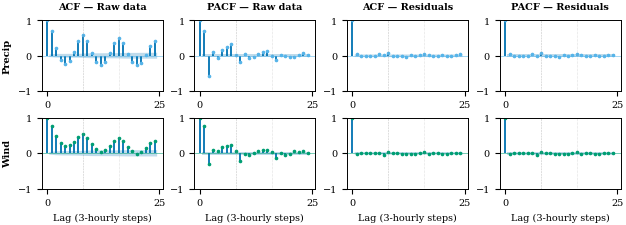

In [17]:
raw_series = {'precip': pd.Series(np.asarray(precip_jittered), index=times_index),
              'wind':   pd.Series(np.asarray(wind_all_grid),   index=times_index)}
var_specs_pw = [(var, raw_series[var].loc[common_idx].values, color)
                for var, color in (('precip', plotting_core.C_PRECIP), ('wind', plotting_core.C_WIND))]
plotting_preprocessing.plot_acf_pacf(var_specs_pw, {var: final_resid[var] for var in ('precip', 'wind')},
                             filename='acf_pacf_lakewide_precipwind.png')

### Raw data vs. deseasonalised vs. deseasonalised + AR

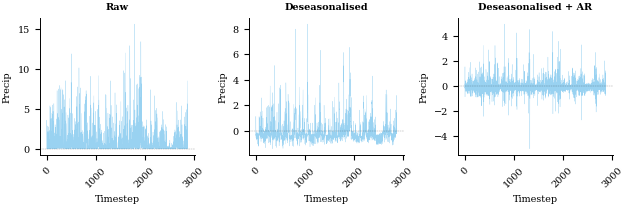

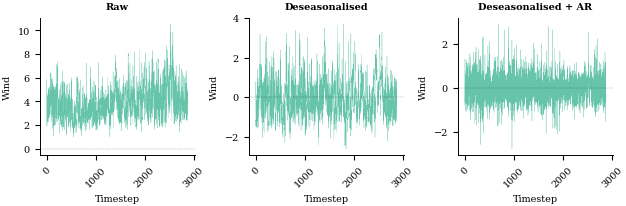

In [18]:
filt_series = {'precip': precip_filt_aligned, 'wind': wind_filt_aligned}
for var in ('precip', 'wind'):
    plotting_preprocessing.plot_deseasonalisation_ar_pipeline(
        var, {'precip': plotting_core.C_PRECIP, 'wind': plotting_core.C_WIND}[var],
        raw_series[var].loc[common_idx].values, filt_series[var].loc[common_idx].values,
        ar_all[var].loc[common_idx].values)

### Residuals before and after adding GARCH

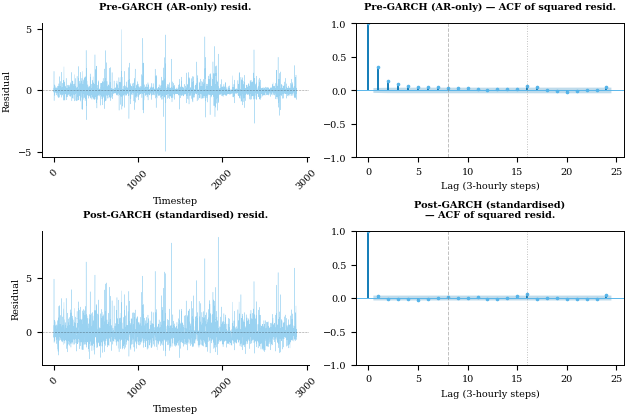

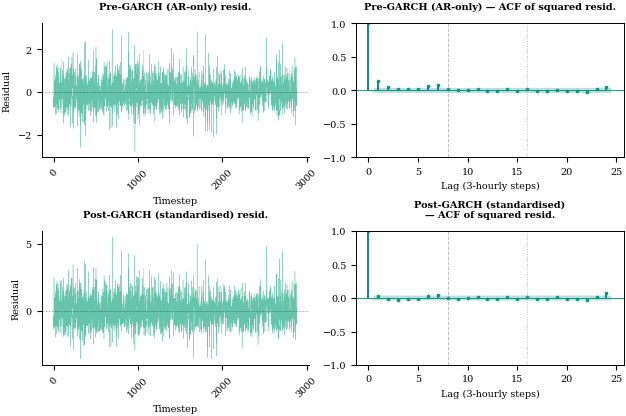

In [19]:
for var in ('precip', 'wind'):
    plotting_preprocessing.plot_pre_post_garch_volatility(
        var, {'precip': plotting_core.C_PRECIP, 'wind': plotting_core.C_WIND}[var],
        ar_all[var].loc[common_idx].values, final_resid[var])

## Save the raw-data artifact

In [20]:
save_artifact(
    "preprocessing",
    precip_aligned=final_resid['precip'], wind_aligned=final_resid['wind'], div_aligned=np.asarray(div_aligned),
    night_mask=night_mask, day_mask=day_mask, common_idx=common_idx, purge_final=purge_final, b_full=b_full,
    precip_all_grid=np.asarray(precip_all_grid), wind_all_grid=np.asarray(wind_all_grid),
    div_all_grid=np.asarray(div_all_grid), time_valid=np.asarray(time_valid),
    precip_flat=precip_flat, wind_flat=wind_flat, div_flat=div_flat, month_flat=month_flat, hour_flat=hour_flat,
    spinup_results=spinup_results, spinup_thresholds=spinup_thresholds,
    lakepts=lakepts, lat_lake=np.asarray(lat_lake), lon_lake=np.asarray(lon_lake),
    lat_sub=np.asarray(lat_sub), lon_sub=np.asarray(lon_sub), lake_sub=np.asarray(lake_sub),
)
print("Saved artifacts/preprocessing_*")

Saved artifacts/preprocessing_*


## Four blocked folds: per-fold preprocessing and kernel-weighted conditional marginals

The pseudo-observations of the main analysis are **conditional on the divergence w through a kernel-weighted ECDF** of each margin (Gaussian kernel, bandwidth h in SD units of w), computed on each fold's training steps only. h is tuned separately within each outer fold using only that fold's training steps by least-squares cross-validation of the conditional PDF (Hall, Racine, & Li, 2004), rescaled to the rate of the conditional CDF as recommended by Li and Racine (2008, Section 2.3, eqs. 13 and 14), with leave-block-out in place of leave-one-out, and then fixed within that fold; h is shared between the two margins of that fold. The binary-regime PIT (ECDF inside the high or low divergence half) and the unconditional PIT are kept as ablations. The median split of w is still returned because the binary-split copula models use it.

In [21]:
from data_split import make_blocked_folds, check_blocked_folds, fold_val_purge

folds = make_blocked_folds(n_pos, purge=purge_final)
cov = check_blocked_folds(folds, n_pos, purge=purge_final)
tt = cov['times_tested']
print(f"n={n_pos}, purge={purge_final}; tested twice: {(tt == 2).sum()}, once: {(tt == 1).sum()}, never: {(tt == 0).sum()}")
print("min train-test distance per fold:", cov['min_gap'])
print("val_purge from largest selected AR lag:", {f['name']: fold_val_purge(int(f['train'].sum()), ar_reach) for f in folds})

n=2884, purge=97; tested twice: 2593, once: 291, never: 0
min train-test distance per fold: {'A1': 98, 'A2': 98, 'B1': 98, 'B2': 98}
val_purge from largest selected AR lag: {'A1': 44, 'A2': 44, 'B1': 44, 'B2': 44}


In [22]:
from preprocessing import fold_regime_pit, tune_kernel_bandwidth, decile_uniformity
groups_fn = lambda r: {
    'all':        np.ones(n_pos, bool),
    'high div':   r['high_mask'],
    'low div':    r['low_mask'],
    'day':        day_mask,
    'night':      night_mask,
    'high&day':   r['high_mask'] & day_mask,
    'low&night':  r['low_mask'] & night_mask,
    'high&night': r['high_mask'] & night_mask,
    'low&day':    r['low_mask'] & day_mask,
}

# pass 1: fold-specific divergence standardisation (residuals come from the full-sample fit, cached in resid_cache)
fold_results, fold_unif = {}, {}
for f in folds:
    r = preprocess_fold(precip_filt_aligned, wind_filt_aligned, div_deseason,
                        hours_full, common_idx, f['train'], max_lags=64, n_starts=20,
                        ar_garch_sample='full', resid_cache=resid_cache)      # h=None: binary-regime PIT; replaced by the kernel-conditional PIT in pass 2
    r['test'] = f['test']
    fold_results[f['name']] = r

# The kernel-conditional PIT bandwidth is chosen inside each outer fold, from that fold's training steps only.
# Both margins share h within a fold. The AR and GARCH residuals are estimated on the full sample.
series = {k: np.asarray(next(iter(fold_results.values()))['final_resid'][k])
          for k in ('precip', 'wind')}
H_BY_FOLD, H_SCORES_BY_FOLD, H_CV_BY_FOLD = {}, {}, {}
for f in folds:
    name = f['name']; r = fold_results[name]
    h_fold, scores = tune_kernel_bandwidth(
        series, {name: r['x_std']}, {name: r['train']}, {name: purge_final})
    if not np.isfinite(h_fold) or h_fold <= 0:
        raise RuntimeError(f"No usable fold-specific PIT bandwidth for {name}")
    H_BY_FOLD[name], H_SCORES_BY_FOLD[name] = h_fold, scores
    H_CV_BY_FOLD[name] = float(scores.attrs['h_cv'])
if any(df.attrs['at_grid_edge'] for df in H_SCORES_BY_FOLD.values()):
    print('WARNING: PIT bandwidth minimum at candidate grid edge; review per-fold scores.')

# pass 2: kernel-weighted conditional PIT using ONLY the target fold's selected h
for f in folds:
    r = fold_results[f['name']]
    h = H_BY_FOLD[f['name']]
    r2 = fold_regime_pit(r['final_resid'], div_deseason, common_idx, f['train'], h=h, min_len=ar_reach)
    r.update({k: v for k, v in r2.items() if k not in ('train',)})
    if r['b'] > purge_final:
        raise RuntimeError(f"Fold {f['name']}: bootstrap diagnostic b={r['b']} exceeds leakage gap L={purge_final}. Increase L and rerun preprocessing before training.")
    rows = []
    for var, key in (('PRECIP u1', 'u1'), ('WIND u2', 'u2'),
                     ('PRECIP u1 (binary-regime PIT)', 'u1_regime'), ('WIND u2 (binary-regime PIT)', 'u2_regime'),
                     ('PRECIP u1 (uncond. PIT)', 'u1_uncond'), ('WIND u2 (uncond. PIT)', 'u2_uncond')):
        for part, m in (('train', f['train']), ('test', f['test'])):
            for g, gm in groups_fn(r).items():
                sel = gm & m
                if sel.sum() > 30:
                    row = uniformity_row(r[key][sel], g); row.update(variable=var, part=part, fold=f['name'])
                    rows.append(row)
            # check 3: uniformity within deciles of w (KS and tail shares)
            for row in decile_uniformity(r[key], r['x_std'], m, 'w'):
                row.update(variable=var, part=part, fold=f['name']); rows.append(row)
    fold_unif[f['name']] = pd.DataFrame(rows)

# ---- two summary tables (everything else is written to csv)
from IPython.display import display, Markdown
display(Markdown("**Table 1. Folds and PIT bandwidth.** For each outer fold: number of training and test steps, the kernel bandwidth h "
                 "of the conditional PIT (in SD units of w) chosen by cross-validation on the training steps (h_cv before the rate "
                 "rescaling), and the share of high-divergence steps. Leakage gap L = %d steps for all folds." % purge_final))
FOLD_TABLE = pd.DataFrame([dict(fold=f['name'], train_n=int(f['train'].sum()), test_n=int(f['test'].sum()),
                                h=H_BY_FOLD[f['name']], h_cv=H_CV_BY_FOLD[f['name']],
                                h_at_grid_edge=bool(H_SCORES_BY_FOLD[f['name']].attrs['at_grid_edge']),
                                high_div_share_train=float(fold_results[f['name']]['high_mask'][f['train']].mean()),
                                high_div_share_test=float(fold_results[f['name']]['high_mask'][f['test']].mean()))
                           for f in folds]).set_index('fold')
reporting_tables.show_table(FOLD_TABLE, 'fold_design_and_pit_bandwidth', title='', digits=3,
                            caption='Folds, selected PIT bandwidth and share of high-divergence steps.')

display(Markdown("**Table 2. Are the pseudo-observations uniform on the test steps?** Kolmogorov-Smirnov distance to U(0,1) of the "
                 "kernel-conditional pseudo-observations (smaller is better). "
                 "'all' uses every test step; 'high div' and 'low div' split by divergence regime; 'worst decile' is the largest "
                 "distance in any of the ten bins of w (each bin holds only a few hundred steps, so this column is larger by construction)."))
_rows = []
for fname_, tab_ in fold_unif.items():
    t_ = tab_[(tab_.part == 'test') & tab_.variable.isin(['PRECIP u1', 'WIND u2'])]
    for var_, g_ in t_.groupby('variable'):
        ks = g_.set_index('group').KS_D
        _rows.append(dict(fold=fname_, variable=var_, all=ks['all'], high_div=ks['high div'], low_div=ks['low div'],
                          worst_decile=g_[g_.group.str.startswith('w decile')].KS_D.max()))
reporting_tables.show_table(pd.DataFrame(_rows), 'pit_uniformity_test_summary', title='', index=False, digits=3,
                            caption='KS distance of the kernel-conditional pseudo-observations on the test steps.')

**Table 1. Folds and PIT bandwidth.** For each outer fold: number of training and test steps, the kernel bandwidth h of the conditional PIT (in SD units of w) chosen by cross-validation on the training steps (h_cv before the rate rescaling), and the share of high-divergence steps. Leakage gap L = 97 steps for all folds.

,train_n,test_n,h,h_cv,h_at_grid_edge,high_div_share_train,high_div_share_test
fold,,,,,,,
A1,1394,1393,0.228,0.291,False,0.5,0.490
A2,1393,1394,0.664,0.845,False,0.5,0.506
B1,1345,1345,0.664,0.845,False,0.5,0.497
B2,1345,1345,0.664,0.845,False,0.5,0.503


**Table 2. Are the pseudo-observations uniform on the test steps?** Kolmogorov-Smirnov distance to U(0,1) of the kernel-conditional pseudo-observations (smaller is better). 'all' uses every test step; 'high div' and 'low div' split by divergence regime; 'worst decile' is the largest distance in any of the ten bins of w (each bin holds only a few hundred steps, so this column is larger by construction).

,fold,variable,all,high_div,low_div,worst_decile
0,A1,PRECIP u1,0.033,0.066,0.036,0.205
1,A1,WIND u2,0.045,0.066,0.073,0.125
2,A2,PRECIP u1,0.027,0.058,0.027,0.182
3,A2,WIND u2,0.048,0.074,0.062,0.147
4,B1,PRECIP u1,0.036,0.043,0.039,0.132
5,B1,WIND u2,0.024,0.038,0.042,0.151
6,B2,PRECIP u1,0.039,0.047,0.033,0.107
7,B2,WIND u2,0.024,0.041,0.050,0.119


,fold,variable,all,high_div,low_div,worst_decile
0,A1,PRECIP u1,0.033389,0.065518,0.035588,0.204548
1,A1,WIND u2,0.045374,0.066031,0.072694,0.125467
2,A2,PRECIP u1,0.027188,0.057887,0.027305,0.182222
3,A2,WIND u2,0.047642,0.073696,0.062072,0.146650
4,B1,PRECIP u1,0.035969,0.042676,0.039097,0.132255
5,B1,WIND u2,0.023957,0.037707,0.042279,0.151427
6,B2,PRECIP u1,0.039303,0.047450,0.033061,0.107048
7,B2,WIND u2,0.024162,0.041012,0.050325,0.119460


### Day/night concordance of the fold-specific regime split

In [23]:
for f in folds:
    r = fold_results[f['name']]
    conc = ((r['high_mask'] & day_mask) | (r['low_mask'] & night_mask)).mean()
    print(f"fold {f['name']}: concordance (high divergence & day, or low divergence & night) = {conc:.1%}")

fold A1: concordance (high divergence & day, or low divergence & night) = 77.4%
fold A2: concordance (high divergence & day, or low divergence & night) = 77.3%
fold B1: concordance (high divergence & day, or low divergence & night) = 77.4%
fold B2: concordance (high divergence & day, or low divergence & night) = 77.3%


In [24]:
for name, r in fold_results.items():
    save_artifact(
        f"preprocessing_fold_{name}",
        u1=r['u1'], u2=r['u2'],
        u1_uncond=r['u1_uncond'], u2_uncond=r['u2_uncond'],
        u1_regime=r['u1_regime'], u2_regime=r['u2_regime'], kernel_h=float(H_BY_FOLD[name]),
        precip_aligned=np.asarray(r['final_resid']['precip']),
        wind_aligned=np.asarray(r['final_resid']['wind']),
        div_aligned=np.asarray(r['div']), x_std=np.asarray(r['x_std']),
        train_mask=np.asarray(r['train']), test_mask=np.asarray(r['test']),
        high_divergence_mask=np.asarray(r['high_mask']),
        low_divergence_mask=np.asarray(r['low_mask']),
        night_mask=night_mask, day_mask=day_mask,
        common_idx=common_idx,
        x_mean=r['x_mean'], x_sd=r['x_sd'], div_median=r['div_median'],
        b=r['b'], purge_final=purge_final,
        ar_lags=r['ar_lags'], vol_model=r['vol_model'],
        uniformity_table=fold_unif[name],
        val_purge=fold_val_purge(int(r['train'].sum()), max(max(lags_) for lags_ in r['ar_lags'].values())),
    )
save_artifact("preprocessing_folds_summary",
              fold_names=[f['name'] for f in folds], kernel_h_by_fold=H_BY_FOLD, kernel_h_scores_by_fold=H_SCORES_BY_FOLD,
              uniformity_all_folds=pd.concat(fold_unif.values(), ignore_index=True),
              fold_coverage_times_tested=tt, fold_min_gap=cov['min_gap'])
print("Saved preprocessing_fold_{A1,A2,B1,B2} and preprocessing_folds_summary")

Saved preprocessing_fold_{A1,A2,B1,B2} and preprocessing_folds_summary


## Table layout

Every table with a tabular is wrapped so that it shrinks to the text width when it is wider and is never enlarged (`reporting_tables.fit_all_tables`); no table needs a manual size edit in the report.

In [25]:
import reporting_tables
print('table files fitted to the text width:', reporting_tables.fit_all_tables())

table files fitted to the text width: ['lb_diagnostics_full.tex']
